In [1]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [2]:

# Install the Hugging Face Transformers library
%pip -q install transformers

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch

from pathlib import Path
from transformers import AutoTokenizer

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())


PyTorch version: 2.11.0+cpu
GPU available: False


In [3]:
# Exact dataset directory
data_dir = Path(
    "/content/drive/MyDrive/Colab_Notebooks/"
    "A_DREAM_JOB/5_Deep_Learning/Product_review_dataset"
)

# Your CSV files do not contain column headers
columns = ["label", "text"]

train_df = pd.read_csv(
    data_dir / "train.csv",
    header=None,
    names=columns
)

valid_df = pd.read_csv(
    data_dir / "valid.csv",
    header=None,
    names=columns
)

test_df = pd.read_csv(
    data_dir / "test.csv",
    header=None,
    names=columns
)

print("Training:", train_df.shape)
print("Validation:", valid_df.shape)
print("Testing:", test_df.shape)

display(train_df.head())


Training: (4182, 2)
Validation: (523, 2)
Testing: (523, 2)


,label,text
0,negative,एंडराॅयड के मामले में यह थोड़ा पीछे है ।
1,neutral,यह एस्पेक्ट रेशो का ईश्यू है और हम आशा करते है...
2,positive,लेकिन इस तरह के एक मॉडल के एक घर कंप्यूटर के ल...
3,positive,गिर वन राष्ट्रीय उद्यान बाघ संरक्षित क्षेत्र ह...
4,neutral,"और हां , इस फिल्म में हर किरदार भारद्वाज को भर..."


Training sentiment distribution:
label
positive    1826
neutral     1789
negative     567
Name: count, dtype: int64

Missing values:
label    0
text     0
dtype: int64

Duplicate rows:
4


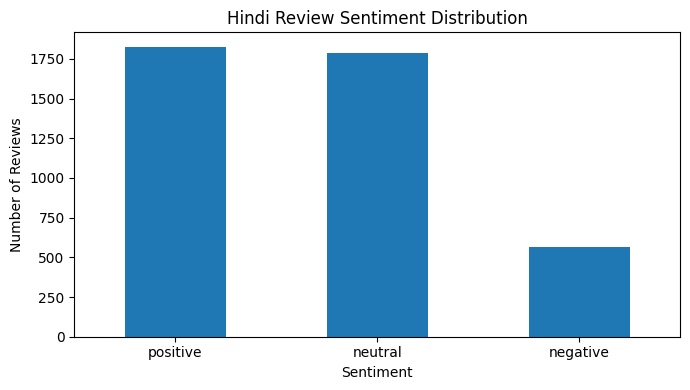

In [4]:
# Exploratory Data Analysis


# Inspect class distribution
print("Training sentiment distribution:")
print(train_df["label"].value_counts())

# Check data quality
print("\nMissing values:")
print(train_df.isnull().sum())

print("\nDuplicate rows:")
print(train_df.duplicated().sum())

# Visualize class imbalance
train_df["label"].value_counts().plot(
    kind="bar",
    figsize=(7, 4),
    title="Hindi Review Sentiment Distribution"
)

plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [5]:
# Basic preprocessing


# Remove exact duplicate training records
train_df = train_df.drop_duplicates().copy()

# Remove unnecessary surrounding whitespace
for df in [train_df, valid_df, test_df]:
    df["text"] = df["text"].str.strip()
    df["label"] = df["label"].str.strip()

# Define consistent numerical class labels
label2id = {
    "negative": 0,
    "neutral": 1,
    "positive": 2
}

id2label = {
    value: key
    for key, value in label2id.items()
}

# Convert text labels into numerical IDs
for df in [train_df, valid_df, test_df]:
    df["label_id"] = df["label"].map(label2id)

    assert df["label_id"].notna().all(), "Unknown label found"

print("Cleaned training rows:", len(train_df))
display(train_df.head())


Cleaned training rows: 4178


,label,text,label_id
0,negative,एंडराॅयड के मामले में यह थोड़ा पीछे है ।,0
1,neutral,यह एस्पेक्ट रेशो का ईश्यू है और हम आशा करते है...,1
2,positive,लेकिन इस तरह के एक मॉडल के एक घर कंप्यूटर के ल...,2
3,positive,गिर वन राष्ट्रीय उद्यान बाघ संरक्षित क्षेत्र ह...,2
4,neutral,"और हां , इस फिल्म में हर किरदार भारद्वाज को भर...",1


In [6]:
# Initialize tokenizer


# Pretrained multilingual BERT checkpoint
model_name = "google-bert/bert-base-multilingual-cased"

# Load its matching tokenizer
tokenizer = AutoTokenizer.from_pretrained(model_name)

# Select a real Hindi review from our dataset
sample_review = train_df.iloc[0]["text"]

print("Original review:")
print(sample_review)

# Convert text into subword tokens
tokens = tokenizer.tokenize(sample_review)

print("\nTokens:")
print(tokens)


config.json:   0%|          | 0.00/625 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.96M [00:00<?, ?B/s]

Original review:
एंडराॅयड के मामले में यह थोड़ा पीछे है ।

Tokens:
['एंड', '##रा', '##ॅ', '##य', '##ड', 'के', 'मा', '##म', '##ले', 'में', 'यह', 'थ', '##ोड़', '##ा', 'पी', '##छ', '##े', 'है', '।']


In [7]:
# Input IDs and attention masks


# Convert a Hindi review into Transformer inputs
encoded = tokenizer(
    sample_review,
    max_length=32,
    padding="max_length",
    truncation=True,
    return_tensors="pt"
)

# Numerical token identifiers
input_ids = encoded["input_ids"]

# Mask: 1 for real tokens, 0 for padding
attention_mask = encoded["attention_mask"]

print("Input IDs shape:", input_ids.shape)
print("Attention mask shape:", attention_mask.shape)

print("\nInput IDs:")
print(input_ids)

print("\nAttention Mask:")
print(attention_mask)


Input IDs shape: torch.Size([1, 32])
Attention mask shape: torch.Size([1, 32])

Input IDs:
tensor([[   101,  88416,  31277, 111209,  13874,  20691,  10412,  32629,  13841,
          13665,  10532,  13525,    881,  89219,  11208,  85166, 108021,  11554,
          10569,    920,    102,      0,      0,      0,      0,      0,      0,
              0,      0,      0,      0,      0]])

Attention Mask:
tensor([[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0,
         0, 0, 0, 0, 0, 0, 0, 0]])


In [8]:
# Create a token analysis table

# Convert token IDs back into readable tokens
decoded_tokens = tokenizer.convert_ids_to_tokens(
    input_ids[0].tolist()
)

# Display tokenization details
token_df = pd.DataFrame({
    "Token": decoded_tokens,
    "Token_ID": input_ids[0].tolist(),
    "Attention_Mask": attention_mask[0].tolist()
})

display(token_df.head(20))


,Token,Token_ID,Attention_Mask
0,[CLS],101,1
1,एंड,88416,1
2,##रा,31277,1
3,##ॅ,111209,1
4,##य,13874,1
5,##ड,20691,1
6,के,10412,1
7,मा,32629,1
8,##म,13841,1
9,##ले,13665,1


In [9]:
# Tokenize an example


import torch
import pandas as pd
import matplotlib.pyplot as plt

# Hindi product review for understanding attention
review = "यह फोन अच्छा है लेकिन बैटरी खराब है।"

# Tokenize without padding for easier visualization
encoded_review = tokenizer(
    review,
    return_tensors="pt",
    truncation=True,
    max_length=32
)

# Extract token IDs
token_ids = encoded_review["input_ids"]

# Convert IDs into readable subword tokens
tokens = tokenizer.convert_ids_to_tokens(
    token_ids[0].tolist()
)

print("Review:", review)
print("Tokens:", tokens)
print("Token IDs shape:", token_ids.shape)


Review: यह फोन अच्छा है लेकिन बैटरी खराब है।
Tokens: ['[CLS]', 'यह', 'फ', '##ोन', 'अ', '##च्छा', 'है', 'लेकिन', 'ब', '##ै', '##टर', '##ी', 'ख', '##रा', '##ब', 'है', '।', '[SEP]']
Token IDs shape: torch.Size([1, 18])


In [10]:
# Create a small embedding layer


import torch.nn as nn

# Set seed for reproducibility
torch.manual_seed(42)

# Embedding dimension for this demonstration
embedding_dim = 8

# Create an embedding layer
embedding_layer = nn.Embedding(
    num_embeddings=tokenizer.vocab_size,
    embedding_dim=embedding_dim
)

# Convert token IDs into embedding vectors
embeddings = embedding_layer(token_ids)

print("Token IDs shape:", token_ids.shape)
print("Embeddings shape:", embeddings.shape)


Token IDs shape: torch.Size([1, 18])
Embeddings shape: torch.Size([1, 18, 8])


In [11]:
# Create Q, K, and V matrices


# Define three learnable linear transformations
query_layer = nn.Linear(embedding_dim, embedding_dim, bias=False)
key_layer = nn.Linear(embedding_dim, embedding_dim, bias=False)
value_layer = nn.Linear(embedding_dim, embedding_dim, bias=False)

# Transform token embeddings into Q, K, V
Q = query_layer(embeddings)
K = key_layer(embeddings)
V = value_layer(embeddings)

print("Query shape:", Q.shape)
print("Key shape:", K.shape)
print("Value shape:", V.shape)


Query shape: torch.Size([1, 18, 8])
Key shape: torch.Size([1, 18, 8])
Value shape: torch.Size([1, 18, 8])


In [12]:
# Scaled dot-product attention


import math

# Dimension of each key vector
d_k = K.shape[-1]

# Calculate similarity between queries and keys
scores = torch.matmul(
    Q,
    K.transpose(-2, -1)
)

# Scale scores for numerical stability
scaled_scores = scores / math.sqrt(d_k)

# Convert scores into attention weights
attention_weights = torch.softmax(
    scaled_scores,
    dim=-1
)

print("Attention scores shape:", scaled_scores.shape)
print("Attention weights shape:", attention_weights.shape)

# Verify that each row sums to approximately 1
print(
    "Row sums:",
    attention_weights.sum(dim=-1)
)


Attention scores shape: torch.Size([1, 18, 18])
Attention weights shape: torch.Size([1, 18, 18])
Row sums: tensor([[1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000,
         1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000]],
       grad_fn=<SumBackward1>)


/usr/local/lib/python3.13/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2351 (\N{DEVANAGARI LETTER YA}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.13/dist-packages/seaborn/utils.py:61: UserWarning: Matplotlib currently does not support Devanagari natively.
  fig.canvas.draw()
/usr/local/lib/python3.13/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2361 (\N{DEVANAGARI LETTER HA}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.13/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2347 (\N{DEVANAGARI LETTER PHA}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.13/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2379 (\N{DEVANAGARI VOWEL SIGN O}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.13/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2344 (\N{DEVANAGARI LETTER NA}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/li

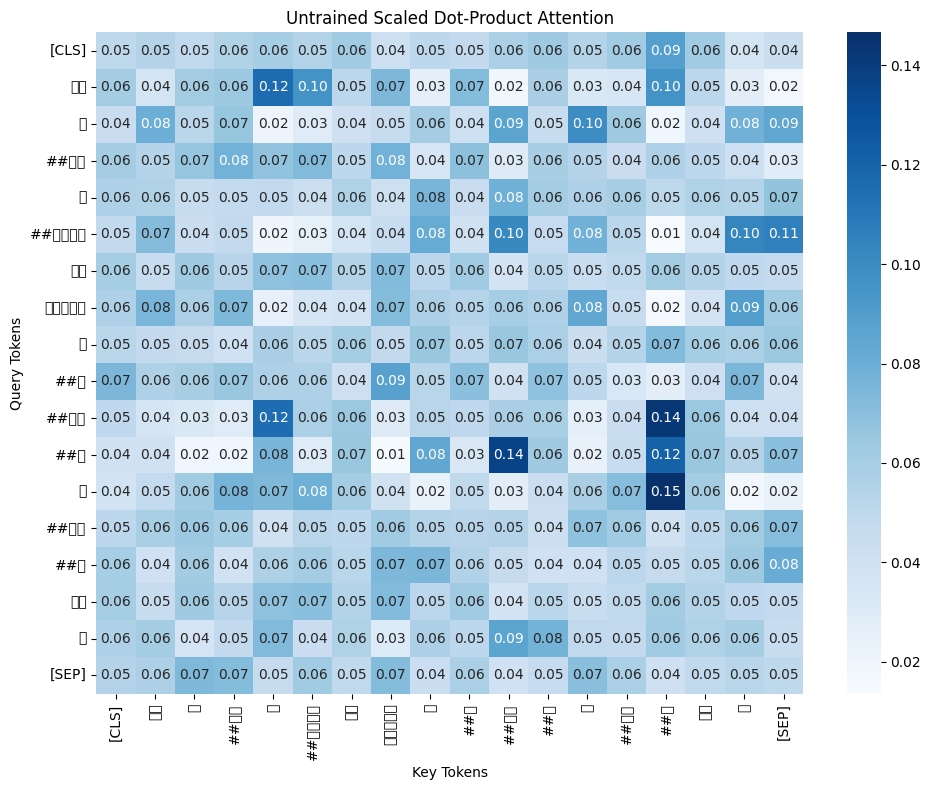

In [13]:
#Attention heatmap


import seaborn as sns

# Remove batch dimension and detach for visualization
attention_matrix = (
    attention_weights[0]
    .detach()
    .numpy()
)

# Visualize token-to-token attention
plt.figure(figsize=(10, 8))

sns.heatmap(
    attention_matrix,
    xticklabels=tokens,
    yticklabels=tokens,
    cmap="Blues",
    annot=True,
    fmt=".2f"
)

plt.xlabel("Key Tokens")
plt.ylabel("Query Tokens")
plt.title("Untrained Scaled Dot-Product Attention")

plt.tight_layout()
plt.show()


In [14]:
# Weighted sum of Value vectors


# Multiply attention weights by Value vectors
attention_output = torch.matmul(
    attention_weights,
    V
)

print("Original embeddings:", embeddings.shape)
print("Attention weights:", attention_weights.shape)
print("Value vectors:", V.shape)
print("Attention output:", attention_output.shape)

# Inspect the contextualized vector for the first token
print(
    "\nFirst token attention output:",
    attention_output[0, 0].detach().numpy()
)


Original embeddings: torch.Size([1, 18, 8])
Attention weights: torch.Size([1, 18, 18])
Value vectors: torch.Size([1, 18, 8])
Attention output: torch.Size([1, 18, 8])

First token attention output: [-0.10675453  0.065042   -0.04099701  0.00607787 -0.0417942   0.17540236
 -0.01004254 -0.10237251]


Query token: यह
Highest-weighted token: अ
Attention weight: 0.1155


/tmp/ipykernel_4624/3334036169.py:33: UserWarning: Glyph 2351 (\N{DEVANAGARI LETTER YA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_4624/3334036169.py:33: UserWarning: Matplotlib currently does not support Devanagari natively.
  plt.tight_layout()
/tmp/ipykernel_4624/3334036169.py:33: UserWarning: Glyph 2361 (\N{DEVANAGARI LETTER HA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_4624/3334036169.py:33: UserWarning: Glyph 2347 (\N{DEVANAGARI LETTER PHA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_4624/3334036169.py:33: UserWarning: Glyph 2379 (\N{DEVANAGARI VOWEL SIGN O}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_4624/3334036169.py:33: UserWarning: Glyph 2344 (\N{DEVANAGARI LETTER NA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_4624/3334036169.py:33: UserWarning: Glyph 2309 (\N{DEVANAGARI LETTER A}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/t

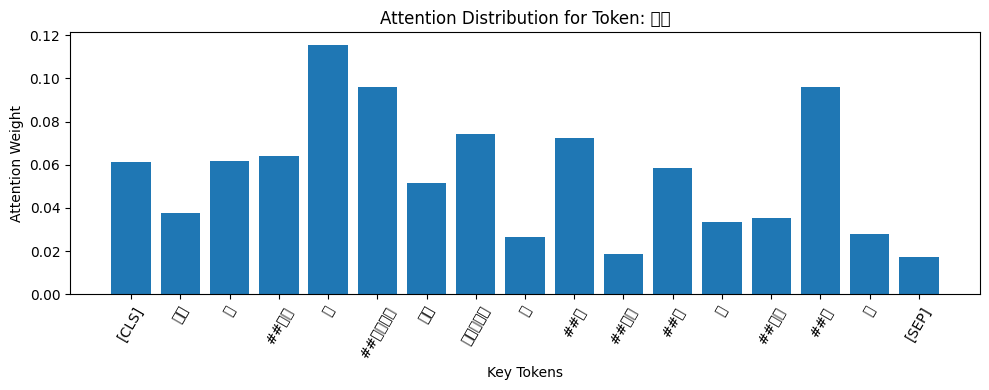

In [15]:
# Inspect one token's attention distribution


# Select the first non-special token
query_index = 1

# Extract its attention weights
token_attention = (
    attention_weights[0, query_index]
    .detach()
    .numpy()
)

# Find the highest-weighted key token
top_index = int(token_attention.argmax())

print("Query token:", tokens[query_index])
print("Highest-weighted token:", tokens[top_index])
print("Attention weight:", round(float(token_attention[top_index]), 4))

# Visualize attention distribution
plt.figure(figsize=(10, 4))

plt.bar(tokens, token_attention)

plt.xlabel("Key Tokens")
plt.ylabel("Attention Weight")
plt.title(
    f"Attention Distribution for Token: {tokens[query_index]}"
)

plt.xticks(rotation=60)
plt.tight_layout()
plt.show()


In [16]:
# Prepare multi-head input


import torch
import torch.nn as nn
import math

# Reproducibility
torch.manual_seed(42)

# Configuration
embed_dim = 32
num_heads = 4
head_dim = embed_dim // num_heads

# Embedding dimension must divide evenly into heads
assert embed_dim % num_heads == 0

# Create token embeddings
multihead_embedding = nn.Embedding(
    num_embeddings=tokenizer.vocab_size,
    embedding_dim=embed_dim
)

# Convert token IDs into embeddings
X = multihead_embedding(token_ids)

print("Input shape:", X.shape)
print("Number of heads:", num_heads)
print("Dimension per head:", head_dim)


Input shape: torch.Size([1, 18, 32])
Number of heads: 4
Dimension per head: 8


In [17]:
# Implement Multi-Head Self-Attention

class MultiHeadSelfAttention(nn.Module):

    def __init__(self, embed_dim=32, num_heads=4):
        super().__init__()

        assert embed_dim % num_heads == 0

        self.num_heads = num_heads
        self.head_dim = embed_dim // num_heads

        # Learnable projections for Query, Key, Value
        self.W_q = nn.Linear(embed_dim, embed_dim)
        self.W_k = nn.Linear(embed_dim, embed_dim)
        self.W_v = nn.Linear(embed_dim, embed_dim)

        # Final projection after combining heads
        self.W_o = nn.Linear(embed_dim, embed_dim)

    def split_heads(self, tensor):
        # Input: (batch, sequence_length, embed_dim)
        batch_size, seq_len, _ = tensor.shape

        # Split embedding dimension across attention heads
        tensor = tensor.reshape(
            batch_size,
            seq_len,
            self.num_heads,
            self.head_dim
        )

        # Output: (batch, heads, sequence_length, head_dim)
        return tensor.transpose(1, 2)

    def forward(self, x, attention_mask=None):

        # Generate Query, Key, and Value
        Q = self.split_heads(self.W_q(x))
        K = self.split_heads(self.W_k(x))
        V = self.split_heads(self.W_v(x))

        # Calculate scaled dot-product scores
        scores = torch.matmul(
            Q,
            K.transpose(-2, -1)
        ) / math.sqrt(self.head_dim)

        # Prevent attention to padding positions
        if attention_mask is not None:
            key_mask = attention_mask[:, None, None, :].bool()

            scores = scores.masked_fill(
                ~key_mask,
                torch.finfo(scores.dtype).min
            )

        # Normalize attention scores
        attention_weights = torch.softmax(scores, dim=-1)

        # Calculate attention outputs
        attention_output = torch.matmul(
            attention_weights,
            V
        )

        # Combine all attention heads
        batch_size, _, seq_len, _ = attention_output.shape

        attention_output = attention_output.transpose(1, 2)

        attention_output = attention_output.reshape(
            batch_size,
            seq_len,
            self.num_heads * self.head_dim
        )

        # Apply final linear projection
        output = self.W_o(attention_output)

        return output, attention_weights


print("Multi-Head Self-Attention class created.")


Multi-Head Self-Attention class created.


In [18]:
# Forward propagation

# Initialize our custom attention layer
attention_layer = MultiHeadSelfAttention(
    embed_dim=32,
    num_heads=4
)

# Get the mask from Exercise 2
review_attention_mask = encoded_review["attention_mask"]

# Forward propagation
output, attention_weights = attention_layer(
    X,
    attention_mask=review_attention_mask
)

print("Input embeddings:", X.shape)
print("Attention output:", output.shape)
print("Attention weights:", attention_weights.shape)


Input embeddings: torch.Size([1, 18, 32])
Attention output: torch.Size([1, 18, 32])
Attention weights: torch.Size([1, 4, 18, 18])


/usr/local/lib/python3.13/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2351 (\N{DEVANAGARI LETTER YA}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.13/dist-packages/seaborn/utils.py:61: UserWarning: Matplotlib currently does not support Devanagari natively.
  fig.canvas.draw()
/usr/local/lib/python3.13/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2361 (\N{DEVANAGARI LETTER HA}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.13/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2347 (\N{DEVANAGARI LETTER PHA}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.13/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2379 (\N{DEVANAGARI VOWEL SIGN O}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.13/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 2344 (\N{DEVANAGARI LETTER NA}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/li

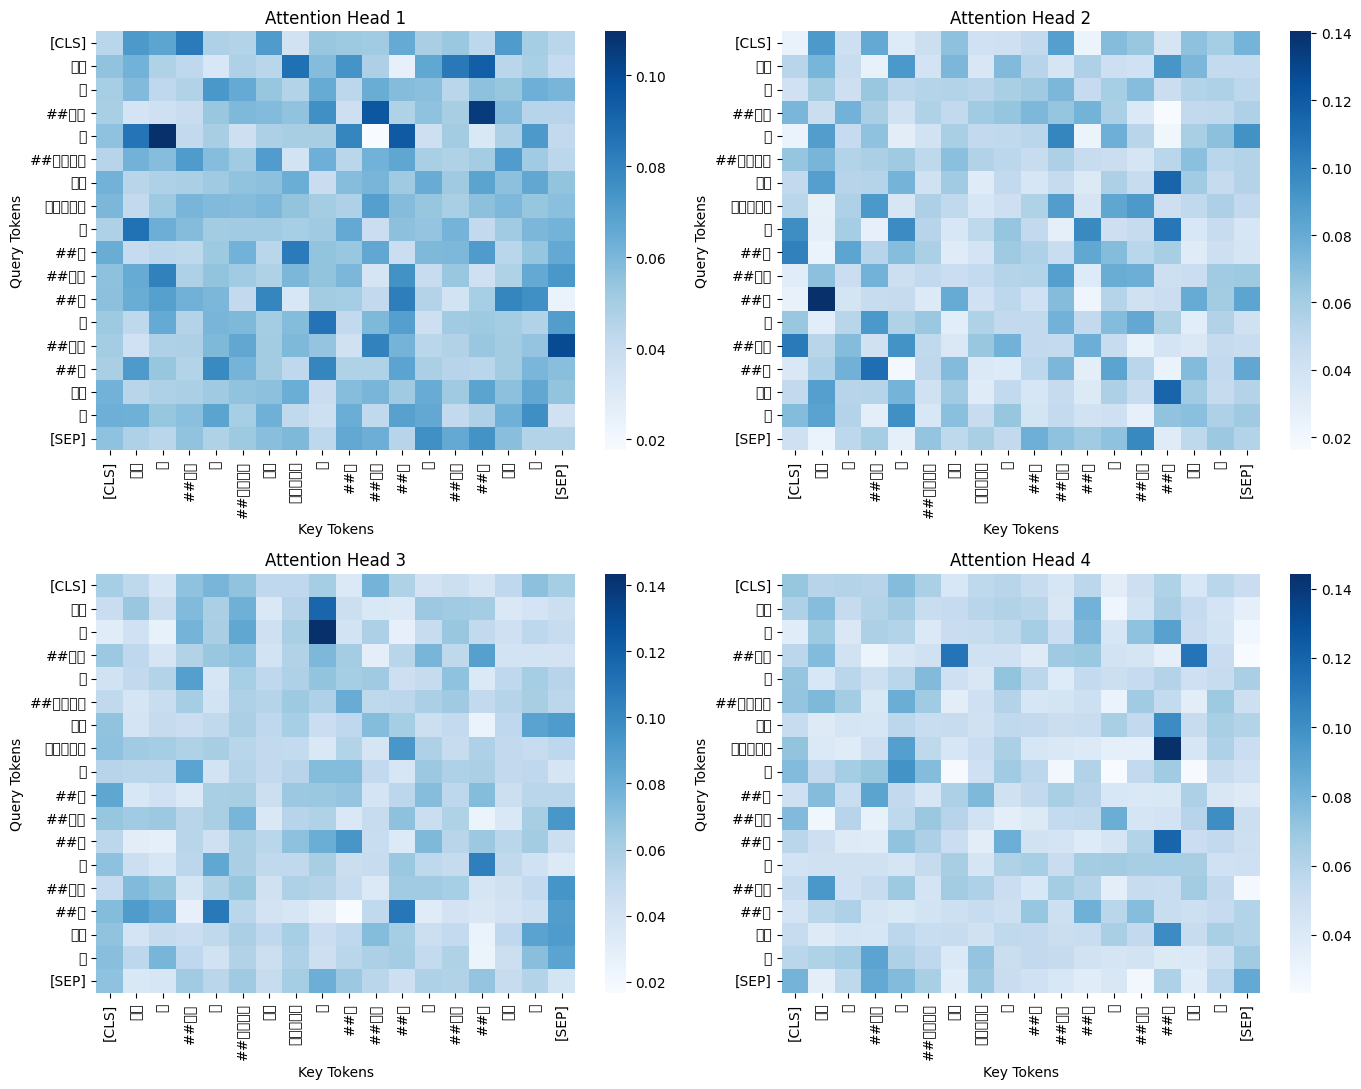

In [19]:
# Attention heatmaps


import matplotlib.pyplot as plt
import seaborn as sns

# Convert attention weights to NumPy
weights = attention_weights[0].detach().numpy()

# Plot four attention heads
fig, axes = plt.subplots(
    2, 2,
    figsize=(14, 11)
)

for head_index, ax in enumerate(axes.flat):

    sns.heatmap(
        weights[head_index],
        xticklabels=tokens,
        yticklabels=tokens,
        cmap="Blues",
        ax=ax
    )

    ax.set_title(f"Attention Head {head_index + 1}")
    ax.set_xlabel("Key Tokens")
    ax.set_ylabel("Query Tokens")

plt.tight_layout()
plt.show()


In [20]:
# Inspect attention diversity


# Select the first non-special token
query_index = 1

# Inspect the highest-weighted token for each head
for head_index in range(num_heads):

    # Attention distribution for this query token
    head_attention = weights[head_index, query_index]

    # Identify the highest attention weight
    top_index = int(head_attention.argmax())

    print(
        f"Head {head_index + 1} | "
        f"Query: {tokens[query_index]} | "
        f"Highest-weighted token: {tokens[top_index]} | "
        f"Weight: {head_attention[top_index]:.4f}"
    )


Head 1 | Query: यह | Highest-weighted token: ##ब | Weight: 0.0930
Head 2 | Query: यह | Highest-weighted token: ##ब | Weight: 0.0914
Head 3 | Query: यह | Highest-weighted token: ब | Weight: 0.1171
Head 4 | Query: यह | Highest-weighted token: ##ी | Weight: 0.0818


In [21]:
# Built-in MultiheadAttention


# Create PyTorch's built-in multi-head attention
builtin_attention = nn.MultiheadAttention(
    embed_dim=32,
    num_heads=4,
    batch_first=True
)

# Forward propagation
builtin_output, builtin_weights = builtin_attention(
    query=X,
    key=X,
    value=X,
    key_padding_mask=~review_attention_mask.bool(),
    need_weights=True,
    average_attn_weights=False
)

print("Custom attention output:", output.shape)
print("Built-in attention output:", builtin_output.shape)

print("Custom attention weights:", attention_weights.shape)
print("Built-in attention weights:", builtin_weights.shape)


Custom attention output: torch.Size([1, 18, 32])
Built-in attention output: torch.Size([1, 18, 32])
Custom attention weights: torch.Size([1, 4, 18, 18])
Built-in attention weights: torch.Size([1, 4, 18, 18])


In [22]:
#Tokenize a batch from your dataset


import torch
import torch.nn as nn
import torch.nn.functional as F

# Use four actual reviews from the training dataset
sample_texts = train_df["text"].head(4).tolist()

# Get their numerical sentiment labels
sample_labels = torch.tensor(
    train_df["label_id"].head(4).tolist(),
    dtype=torch.long
)

# Tokenize with fixed-length padding
encoded_batch = tokenizer(
    sample_texts,
    padding="max_length",
    truncation=True,
    max_length=64,
    return_tensors="pt"
)

input_ids = encoded_batch["input_ids"]
attention_mask = encoded_batch["attention_mask"]

print("Input IDs:", input_ids.shape)
print("Attention Mask:", attention_mask.shape)
print("Labels:", sample_labels.shape)


Input IDs: torch.Size([4, 64])
Attention Mask: torch.Size([4, 64])
Labels: torch.Size([4])


In [23]:
# Embedding layer


class TransformerEmbedding(nn.Module):

    def __init__(self, vocab_size, embed_dim, max_length):
        super().__init__()

        # Convert token IDs into dense vectors
        self.token_embedding = nn.Embedding(
            vocab_size,
            embed_dim
        )

        # Learn positional representations
        self.position_embedding = nn.Embedding(
            max_length,
            embed_dim
        )

    def forward(self, input_ids):

        batch_size, seq_length = input_ids.shape

        # Generate position indices: 0, 1, 2, ...
        positions = torch.arange(
            seq_length,
            device=input_ids.device
        ).unsqueeze(0)

        # Combine token and positional information
        return (
            self.token_embedding(input_ids)
            + self.position_embedding(positions)
        )


# Create the embedding layer
embedding = TransformerEmbedding(
    vocab_size=tokenizer.vocab_size,
    embed_dim=64,
    max_length=64
)

# Generate embeddings
embedded_inputs = embedding(input_ids)

print("Embedding output:", embedded_inputs.shape)


Embedding output: torch.Size([4, 64, 64])


In [24]:
#Transformer encoder implementation


class TransformerEncoderBlock(nn.Module):

    def __init__(self, embed_dim=64, num_heads=4):
        super().__init__()

        # Multi-head self-attention
        self.attention = nn.MultiheadAttention(
            embed_dim=embed_dim,
            num_heads=num_heads,
            batch_first=True
        )

        # Feed-forward neural network
        self.feed_forward = nn.Sequential(
            nn.Linear(embed_dim, embed_dim * 4),
            nn.ReLU(),
            nn.Linear(embed_dim * 4, embed_dim)
        )

        # Layer normalization
        self.norm1 = nn.LayerNorm(embed_dim)
        self.norm2 = nn.LayerNorm(embed_dim)

        # Regularization
        self.dropout = nn.Dropout(0.1)

    def forward(self, x, attention_mask):

        # True indicates a padding position
        padding_mask = ~attention_mask.bool()

        # Multi-head self-attention
        attention_output, _ = self.attention(
            query=x,
            key=x,
            value=x,
            key_padding_mask=padding_mask,
            need_weights=False
        )

        # Residual connection + normalization
        x = self.norm1(
            x + self.dropout(attention_output)
        )

        # Feed-forward transformation
        ff_output = self.feed_forward(x)

        # Second residual connection + normalization
        x = self.norm2(
            x + self.dropout(ff_output)
        )

        return x


print("Transformer encoder block created.")


Transformer encoder block created.


In [25]:
#Transformer classification model


class HindiSentimentTransformer(nn.Module):

    def __init__(
        self,
        vocab_size,
        embed_dim=64,
        num_heads=4,
        num_classes=3,
        max_length=64
    ):
        super().__init__()

        # Token + positional embeddings
        self.embedding = TransformerEmbedding(
            vocab_size,
            embed_dim,
            max_length
        )

        # Transformer encoder
        self.encoder = TransformerEncoderBlock(
            embed_dim,
            num_heads
        )

        # Classification head
        self.classifier = nn.Linear(
            embed_dim,
            num_classes
        )

    def forward(self, input_ids, attention_mask):

        # Step 1: Embeddings
        x = self.embedding(input_ids)

        # Step 2: Contextual representations
        x = self.encoder(x, attention_mask)

        # Step 3: Masked mean pooling
        # Exclude padding tokens from the average
        mask = attention_mask.unsqueeze(-1).float()

        pooled = (x * mask).sum(dim=1) / (
            mask.sum(dim=1).clamp(min=1)
        )

        # Step 4: Three sentiment logits
        logits = self.classifier(pooled)

        return logits


# Set seed for reproducibility
torch.manual_seed(42)

# Initialize the model
custom_model = HindiSentimentTransformer(
    vocab_size=tokenizer.vocab_size,
    embed_dim=64,
    num_heads=4,
    num_classes=3,
    max_length=64
)

print("Custom Transformer classifier created.")


Custom Transformer classifier created.


In [26]:
#Generate sentiment logits


# Switch to evaluation mode for demonstration
custom_model.eval()

# Forward propagation without gradient tracking
with torch.no_grad():

    logits = custom_model(
        input_ids=input_ids,
        attention_mask=attention_mask
    )

    # Convert logits into probabilities
    probabilities = torch.softmax(logits, dim=1)

    # Get predicted class indices
    predictions = torch.argmax(probabilities, dim=1)

print("Input shape:", input_ids.shape)
print("Output logits:", logits.shape)
print("Probabilities:", probabilities.shape)
print("Predicted labels:", predictions.tolist())


Input shape: torch.Size([4, 64])
Output logits: torch.Size([4, 3])
Probabilities: torch.Size([4, 3])
Predicted labels: [0, 0, 0, 0]


In [27]:
# Compare actual and predicted sentiments


# Convert predictions into sentiment labels
predicted_sentiments = [
    id2label[int(pred)]
    for pred in predictions
]

# Convert actual labels into sentiment names
actual_sentiments = [
    id2label[int(label)]
    for label in sample_labels
]

# Build comparison table
results_df = pd.DataFrame({
    "Review": sample_texts,
    "Actual": actual_sentiments,
    "Predicted": predicted_sentiments,
    "Confidence": probabilities.max(dim=1).values.tolist()
})

display(results_df)


,Review,Actual,Predicted,Confidence
0,एंडराॅयड के मामले में यह थोड़ा पीछे है ।,negative,negative,0.436135
1,यह एस्पेक्ट रेशो का ईश्यू है और हम आशा करते है...,neutral,negative,0.409389
2,लेकिन इस तरह के एक मॉडल के एक घर कंप्यूटर के ल...,positive,negative,0.405684
3,गिर वन राष्ट्रीय उद्यान बाघ संरक्षित क्षेत्र ह...,positive,negative,0.395520


In [28]:
#Test the complete forward-and-loss pipeline

# Cross-entropy loss for three-class classification
criterion = nn.CrossEntropyLoss()

# Compare logits with actual sentiment labels
loss = criterion(logits, sample_labels)

print("Batch size:", len(sample_labels))
print("Number of sentiment classes:", logits.shape[1])
print("Cross-Entropy Loss:", loss.item())


Batch size: 4
Number of sentiment classes: 3
Cross-Entropy Loss: 1.1530969142913818


In [29]:
#Count trainable parameters


# Count all trainable parameters
total_params = sum(
    parameter.numel()
    for parameter in custom_model.parameters()
    if parameter.requires_grad
)

print(f"Trainable parameters: {total_params:,}")

print("\nModel architecture:")
print(custom_model)


Trainable parameters: 7,705,283

Model architecture:
HindiSentimentTransformer(
  (embedding): TransformerEmbedding(
    (token_embedding): Embedding(119547, 64)
    (position_embedding): Embedding(64, 64)
  )
  (encoder): TransformerEncoderBlock(
    (attention): MultiheadAttention(
      (out_proj): NonDynamicallyQuantizableLinear(in_features=64, out_features=64, bias=True)
    )
    (feed_forward): Sequential(
      (0): Linear(in_features=64, out_features=256, bias=True)
      (1): ReLU()
      (2): Linear(in_features=256, out_features=64, bias=True)
    )
    (norm1): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
    (norm2): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (classifier): Linear(in_features=64, out_features=3, bias=True)
)


In [30]:

import torch

# Select GPU when available
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Training device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Warning: BERT training will be slower on CPU.")


Training device: cpu


In [31]:
#Prepare training, validation, and test inputs


# Maximum number of tokens per review
MAX_LENGTH = 128

def tokenize_reviews(df):
    """
    Convert Hindi reviews into BERT-compatible inputs.
    """

    return tokenizer(
        df["text"].tolist(),
        padding="max_length",
        truncation=True,
        max_length=MAX_LENGTH,
        return_tensors="pt"
    )

# Tokenize all three datasets
train_encodings = tokenize_reviews(train_df)
valid_encodings = tokenize_reviews(valid_df)
test_encodings = tokenize_reviews(test_df)

print("Training input shape:", train_encodings["input_ids"].shape)
print("Validation input shape:", valid_encodings["input_ids"].shape)
print("Test input shape:", test_encodings["input_ids"].shape)


Training input shape: torch.Size([4178, 128])
Validation input shape: torch.Size([523, 128])
Test input shape: torch.Size([523, 128])


In [32]:
#Build a reusable Dataset class


from torch.utils.data import Dataset, DataLoader

class HindiReviewDataset(Dataset):

    def __init__(self, encodings, labels):

        self.encodings = encodings

        self.labels = torch.tensor(
            labels,
            dtype=torch.long
        )

    def __len__(self):

        return len(self.labels)

    def __getitem__(self, index):

        # Retrieve BERT input tensors
        item = {
            key: value[index]
            for key, value in self.encodings.items()
        }

        # Add numerical sentiment label
        item["labels"] = self.labels[index]

        return item


# Create dataset objects
train_dataset = HindiReviewDataset(
    train_encodings,
    train_df["label_id"].tolist()
)

valid_dataset = HindiReviewDataset(
    valid_encodings,
    valid_df["label_id"].tolist()
)

test_dataset = HindiReviewDataset(
    test_encodings,
    test_df["label_id"].tolist()
)

print("Training examples:", len(train_dataset))
print("Validation examples:", len(valid_dataset))
print("Test examples:", len(test_dataset))


Training examples: 4178
Validation examples: 523
Test examples: 523


In [33]:
# Mini-batch configuration


# Small batch size to reduce GPU memory usage
BATCH_SIZE = 8

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

valid_loader = DataLoader(
    valid_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

# Inspect one training batch
batch = next(iter(train_loader))

print("Input IDs:", batch["input_ids"].shape)
print("Attention Mask:", batch["attention_mask"].shape)
print("Labels:", batch["labels"].shape)


Input IDs: torch.Size([8, 128])
Attention Mask: torch.Size([8, 128])
Labels: torch.Size([8])


In [34]:
# Initialize the classification model


from transformers import AutoModelForSequenceClassification

# Use the same pretrained checkpoint as our tokenizer
model_name = "google-bert/bert-base-multilingual-cased"

# Load pretrained BERT with a new 3-class classification head
bert_model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=3,
    id2label=id2label,
    label2id=label2id
)

# Move model to GPU or CPU
bert_model = bert_model.to(device)

print("Pretrained multilingual BERT loaded.")
print("Device:", next(bert_model.parameters()).device)


model.safetensors: reconstructing file:   0%|          |  0.00B /  714MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: google-bert/bert-base-multilingual-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.

Pretrained multilingual BERT loaded.
Device: cpu


In [35]:
#AdamW optimizer


from torch.optim import AdamW

# Fine-tuning learning rate
LEARNING_RATE = 2e-5

# Start with 2 epochs for this learning exercise
EPOCHS = 2

# AdamW optimizer
optimizer = AdamW(
    bert_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=0.01
)

print("Optimizer: AdamW")
print("Learning rate:", LEARNING_RATE)
print("Epochs:", EPOCHS)
print("Batch size:", BATCH_SIZE)


Optimizer: AdamW
Learning rate: 2e-05
Epochs: 2
Batch size: 8


In [36]:
#Evaluate loss and Macro F1


from sklearn.metrics import accuracy_score, f1_score

def evaluate_bert(model, data_loader):

    # Switch model to evaluation mode
    model.eval()

    total_loss = 0.0
    all_predictions = []
    all_labels = []

    # Disable gradient calculations
    with torch.no_grad():

        for batch in data_loader:

            # Move tensors to the selected device
            batch = {
                key: value.to(device)
                for key, value in batch.items()
            }

            # Forward propagation
            outputs = model(**batch)

            # Calculate predictions
            predictions = torch.argmax(
                outputs.logits,
                dim=1
            )

            # Accumulate sample-weighted loss
            batch_size = batch["labels"].size(0)

            total_loss += outputs.loss.item() * batch_size

            all_predictions.extend(
                predictions.cpu().tolist()
            )

            all_labels.extend(
                batch["labels"].cpu().tolist()
            )

    # Average loss per example
    avg_loss = total_loss / len(data_loader.dataset)

    # Calculate accuracy
    accuracy = accuracy_score(
        all_labels,
        all_predictions
    )

    # Calculate Macro F1
    macro_f1 = f1_score(
        all_labels,
        all_predictions,
        labels=[0, 1, 2],
        average="macro",
        zero_division=0
    )

    return avg_loss, accuracy, macro_f1


print("Validation function created.")


Validation function created.


In [ ]:
#Training loop


from tqdm.auto import tqdm

# Store training history
history = {
    "train_loss": [],
    "val_loss": [],
    "val_accuracy": [],
    "val_f1": []
}

# Save the best model based on validation Macro F1
best_f1 = -1.0

best_model_dir = (
    data_dir.parent / "hindi_bert_sentiment_model"
)

for epoch in range(EPOCHS):

    # Enable training mode
    bert_model.train()

    total_train_loss = 0.0

    progress_bar = tqdm(
        train_loader,
        desc=f"Epoch {epoch + 1}/{EPOCHS}"
    )

    for batch in progress_bar:

        # Move batch to GPU or CPU
        batch = {
            key: value.to(device)
            for key, value in batch.items()
        }

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward propagation and loss calculation
        outputs = bert_model(**batch)

        loss = outputs.loss

        # Backpropagation
        loss.backward()

        # Prevent excessively large gradients
        torch.nn.utils.clip_grad_norm_(
            bert_model.parameters(),
            max_norm=1.0
        )

        # Update model weights
        optimizer.step()

        # Accumulate sample-weighted training loss
        batch_size = batch["labels"].size(0)

        total_train_loss += loss.item() * batch_size

        progress_bar.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    # Calculate average training loss
    train_loss = total_train_loss / len(train_dataset)

    # Validate after each epoch
    val_loss, val_accuracy, val_f1 = evaluate_bert(
        bert_model,
        valid_loader
    )

    # Store metrics
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_accuracy)
    history["val_f1"].append(val_f1)

    print(
        f"\nEpoch {epoch + 1}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.2%} | "
        f"Val Macro F1: {val_f1:.4f}"
    )

    # Save checkpoint when validation Macro F1 improves
    if val_f1 > best_f1:

        best_f1 = val_f1

        bert_model.save_pretrained(best_model_dir)

        tokenizer.save_pretrained(best_model_dir)

        print("Best model checkpoint saved.")

print("\nFine-tuning completed.")
print("Best validation Macro F1:", round(best_f1, 4))


Epoch 1/2:   0%|          | 0/523 [00:00<?, ?it/s]

In [ ]:
#Training and validation curves


# Epoch numbers
epoch_numbers = range(1, EPOCHS + 1)

# Plot training and validation loss
plt.figure(figsize=(9, 4))

plt.plot(
    epoch_numbers,
    history["train_loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    epoch_numbers,
    history["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.title("Multilingual BERT — Training vs Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Plot validation accuracy and Macro F1
plt.figure(figsize=(9, 4))

plt.plot(
    epoch_numbers,
    history["val_accuracy"],
    marker="o",
    label="Validation Accuracy"
)

plt.plot(
    epoch_numbers,
    history["val_f1"],
    marker="o",
    label="Validation Macro F1"
)

plt.xlabel("Epoch")
plt.ylabel("Score")
plt.title("Multilingual BERT — Validation Performance")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [ ]:
# Training summary

# Find epoch with highest validation Macro F1
best_epoch = int(np.argmax(history["val_f1"]))

print("Best epoch:", best_epoch + 1)

print(
    "Validation Accuracy:",
    f"{history['val_accuracy'][best_epoch]:.2%}"
)

print(
    "Validation Macro F1:",
    f"{history['val_f1'][best_epoch]:.4f}"
)

print("Saved model directory:", best_model_dir)


In [ ]:
# Restore the fine-tuned Transformer


from transformers import AutoModelForSequenceClassification, AutoTokenizer

# Load the best checkpoint saved during Exercise 5
best_model = AutoModelForSequenceClassification.from_pretrained(
    best_model_dir
).to(device)

# Load its matching tokenizer
best_tokenizer = AutoTokenizer.from_pretrained(
    best_model_dir
)

# Enable inference mode
best_model.eval()

print("Best model loaded successfully.")
print("Device:", device)
print("Sentiment labels:", best_model.config.id2label)


In [ ]:
# Calculate final test metrics


from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Evaluate the held-out test set exactly once
test_loss, test_accuracy, test_macro_f1 = evaluate_bert(
    best_model,
    test_loader
)

print("FINAL TEST RESULTS")
print("-" * 35)

print(f"Test Loss:     {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.2%}")
print(f"Test Macro F1: {test_macro_f1:.4f}")


In [ ]:
# Collect predicted and actual labels


# Store predictions and actual sentiment labels
all_predictions = []
all_actuals = []
all_probabilities = []

best_model.eval()

with torch.no_grad():

    for batch in test_loader:

        # Move input tensors to GPU or CPU
        inputs = {
            key: value.to(device)
            for key, value in batch.items()
            if key != "labels"
        }

        # Generate sentiment logits
        outputs = best_model(**inputs)

        # Convert logits into probabilities
        probabilities = torch.softmax(
            outputs.logits,
            dim=1
        )

        # Select the most probable class
        predictions = probabilities.argmax(dim=1)

        all_predictions.extend(
            predictions.cpu().tolist()
        )

        all_actuals.extend(
            batch["labels"].tolist()
        )

        all_probabilities.extend(
            probabilities.cpu().tolist()
        )

print("Total test predictions:", len(all_predictions))
print("Total actual labels:", len(all_actuals))

assert len(all_predictions) == len(test_df)


In [ ]:
# Classification report


from sklearn.metrics import classification_report

# Evaluate precision, recall, and F1 for each sentiment
report = classification_report(
    all_actuals,
    all_predictions,
    labels=[0, 1, 2],
    target_names=["Negative", "Neutral", "Positive"],
    digits=4,
    zero_division=0
)

print("CLASSIFICATION REPORT")
print(report)


In [ ]:
# Confusion matrix


from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Create confusion matrix
cm = confusion_matrix(
    all_actuals,
    all_predictions,
    labels=[0, 1, 2]
)

# Visualize classification errors
plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Neutral", "Positive"],
    yticklabels=["Negative", "Neutral", "Positive"]
)

plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.title("Hindi Product Review — Confusion Matrix")

plt.tight_layout()
plt.show()


In [ ]:
# Find misclassified reviews


# Create a detailed test results DataFrame
results_df = test_df.copy().reset_index(drop=True)

# Add predicted numerical labels
results_df["predicted_id"] = all_predictions

# Convert predictions into sentiment names
results_df["predicted_label"] = results_df["predicted_id"].map(
    id2label
)

# Add maximum softmax score
results_df["max_probability"] = [
    max(probs)
    for probs in all_probabilities
]

# Identify incorrect predictions
results_df["is_correct"] = (
    results_df["label_id"] == results_df["predicted_id"]
)

# Extract misclassified reviews
errors_df = results_df[
    ~results_df["is_correct"]
].copy()

print("Total test reviews:", len(results_df))
print("Incorrect predictions:", len(errors_df))

display(
    errors_df[
        ["text", "label", "predicted_label", "max_probability"]
    ].head(10)
)


In [ ]:
# Predict new Hindi product reviews


def predict_hindi_sentiment(review):
    """
    Predict sentiment for one Hindi product review.
    Returns sentiment and class probabilities.
    """

    # Convert review into BERT input tensors
    encoded = best_tokenizer(
        review,
        return_tensors="pt",
        truncation=True,
        max_length=MAX_LENGTH
    )

    # Move tensors to model device
    encoded = {
        key: value.to(device)
        for key, value in encoded.items()
    }

    # Perform inference
    best_model.eval()

    with torch.no_grad():

        outputs = best_model(**encoded)

        probabilities = torch.softmax(
            outputs.logits,
            dim=1
        )[0]

    # Identify predicted class
    predicted_id = int(probabilities.argmax().item())

    return {
        "review": review,
        "sentiment": id2label[predicted_id],
        "probabilities": {
            id2label[i]: round(float(probabilities[i]), 4)
            for i in range(3)
        }
    }


print("Prediction function ready.")


In [ ]:
#Real-world inference


# Example reviews not taken from the training DataFrame
new_reviews = [
    "यह फोन बहुत अच्छा है और कैमरा शानदार है।",
    "बैटरी बहुत खराब है और फोन जल्दी बंद हो जाता है।",
    "प्रोडक्ट ठीक है, लेकिन कुछ खास नहीं है।",
    "डिलीवरी अच्छी थी लेकिन प्रोडक्ट की क्वालिटी खराब है।"
]

# Predict sentiment for each review
prediction_results = []

for review in new_reviews:

    result = predict_hindi_sentiment(review)

    prediction_results.append({
        "Review": result["review"],
        "Predicted Sentiment": result["sentiment"],
        "Negative Probability": result["probabilities"]["negative"],
        "Neutral Probability": result["probabilities"]["neutral"],
        "Positive Probability": result["probabilities"]["positive"]
    })

display(pd.DataFrame(prediction_results))


In [ ]:
#Analyze predicted sentiment distribution


# Count predicted sentiments in the held-out test set
sentiment_counts = (
    results_df["predicted_label"]
    .value_counts()
    .reindex(["negative", "neutral", "positive"], fill_value=0)
)

# Convert counts into percentages
sentiment_percentages = (
    sentiment_counts / len(results_df) * 100
)

# Create business summary
business_summary = pd.DataFrame({
    "Predicted Reviews": sentiment_counts,
    "Percentage": sentiment_percentages.round(2)
})

display(business_summary)

# Visualize distribution
plt.figure(figsize=(8, 4))

sentiment_counts.plot(kind="bar")

plt.title("Predicted Sentiment Distribution — Test Dataset")
plt.xlabel("Predicted Sentiment")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [ ]:
#Automated business conclusion

# Extract per-class performance
metrics = classification_report(
    all_actuals,
    all_predictions,
    labels=[0, 1, 2],
    target_names=["negative", "neutral", "positive"],
    output_dict=True,
    zero_division=0
)

negative_recall = metrics["negative"]["recall"]
negative_precision = metrics["negative"]["precision"]

print("=" * 50)
print("FINAL TRANSFORMER PROJECT SUMMARY")
print("=" * 50)

print(f"Model: {model_name}")
print(f"Training reviews: {len(train_df)}")
print(f"Validation reviews: {len(valid_df)}")
print(f"Test reviews: {len(test_df)}")

print(f"\nTest Accuracy: {test_accuracy:.2%}")
print(f"Test Macro F1: {test_macro_f1:.4f}")

print(f"\nNegative Precision: {negative_precision:.2%}")
print(f"Negative Recall: {negative_recall:.2%}")

print(f"\nMisclassified reviews: {len(errors_df)}")

print("\nBUSINESS CONCLUSION")

if test_macro_f1 >= 0.85:
    print(
        "Strong initial test performance. "
        "Proceed to external validation and monitoring."
    )

elif test_macro_f1 >= 0.70:
    print(
        "Promising baseline. Improve minority-class "
        "performance and investigate errors."
    )

else:
    print(
        "Model needs improvement before operational use. "
        "Investigate label quality, truncation and class imbalance."
    )

print(
    "\nRecommendation: Review Negative Recall before "
    "using the model to prioritize customer complaints."
)
